# 🌊 MAHA JAL KHOJ: Maharashtra Groundwater Intelligence
## Part 1: Comprehensive Exploratory Data Analysis & Spatial-Temporal Visualization

### 📌 Project Overview
This notebook presents an end-to-end hydrogeological data analysis of the **Digital Water Level Recorder (DWLR)** telemetry dataset collected across the State of Maharashtra, India. The dataset captures 6-hourly automated water level observations across **34 districts**, **304 tehsils**, and **1,016 monitoring stations** between **January 1, 2026 and May 30, 2026** (the critical pre-monsoon dry season).

---

### 🎯 Notebook Objectives
1. **Data Ingestion & Schema Audit**: Parse and explain every column in the telemetry stream.
2. **Telemetry Anomaly & Sensor Error Detection**: Identify known telemetry glitch codes (e.g., the `1.000m` placeholder probe code and extreme values).
3. **Depth Standardization**: Standardize negative/positive sign conventions into true positive **Depth Below Ground Level (`Depth_mbgl`)**.
4. **Spatial Density Audit**: Quantify geographic sampling imbalances (e.g., Sangli with 92 stations vs. Dhule with 4 stations).
5. **Alert Framework Definition**: Establish Central Ground Water Board (CGWB) alert parameters (Flood, Safe, Normal, Moderate Drought, Severe Drought).
6. **Publication-Quality Visualizations**: Plot statewide distributions, depletion curves, and district vulnerability rankings.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure aesthetics
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.sans-serif': 'DejaVu Sans',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'figure.titlesize': 15
})

CSV_FILE = "../gwl_tel_6_hourly_maharashtra_gw_mh_2026_2030 (1).csv"
if not os.path.exists(CSV_FILE):
    CSV_FILE = "gwl_tel_6_hourly_maharashtra_gw_mh_2026_2030 (1).csv"

print(f"Loading telemetry file from: {CSV_FILE}")
df = pd.read_csv(CSV_FILE, low_memory=False)
df.columns = df.columns.str.strip()
print(f"Dataset successfully loaded: {len(df):,} rows and {len(df.columns)} columns.")


Loading telemetry file from: ../gwl_tel_6_hourly_maharashtra_gw_mh_2026_2030 (1).csv


Dataset successfully loaded: 218,791 rows and 21 columns.


### 1. Dataset Dimensions & Schema Inspection
Let's inspect the columns, data types, and initial records. In Indian telemetry networks, groundwater level is recorded by automated pressure transducers mounted inside borewells/piezometers.


In [2]:
# Display basic info and first 5 rows
print("Columns in Dataset:")
for col in df.columns:
    print(f" - {col}")

display(df[['Station', 'District', 'Tehsil', 'Latitude', 'Longitude', 'RL_MSL', 'Data Acquisition Time', 'Groundwater Level Telemetry 6 Hourly (meter)']].head(5))


Columns in Dataset:
 - SlNo
 - Station
 - Agency
 - State LGD Code
 - State
 - District LGD Code
 - District
 - Tehsil
 - Block
 - Village
 - River
 - Basin
 - Tributary
 - Subtributary
 - SubSubtributary
 - Local River
 - Latitude
 - Longitude
 - RL_MSL
 - Data Acquisition Time
 - Groundwater Level Telemetry 6 Hourly (meter)


,Station,District,Tehsil,Latitude,Longitude,RL_MSL,Data Acquisition Time,Groundwater Level Telemetry 6 Hourly (meter)
0,AALEGAON,Akola,Patur,20.402778,76.845836,411.0,01-01-2026 00:00,-5.965
1,AALEGAON,Akola,Patur,20.402778,76.845836,411.0,01-01-2026 06:00,-6.025
2,AALEGAON,Akola,Patur,20.402778,76.845836,411.0,01-01-2026 12:00,-6.420
3,AALEGAON,Akola,Patur,20.402778,76.845836,411.0,01-01-2026 18:00,-6.056
4,AALEGAON,Akola,Patur,20.402778,76.845836,411.0,02-01-2026 00:00,-6.837


### 2. Sensor Anomaly & Error Code Detection
In real-world IoT telemetry datasets, sensors occasionally malfunction, disconnect, or transmit placeholder error codes.

#### Key Discovery: The `1.000` Placeholder Code
In GSDA / CGWB telemetry systems, when a piezometric probe is uncalibrated, submerged in sludge, or disconnected, it transmits a default uncalibrated state of **`1.000000 m`**. If not removed, an alert system would wrongly flag thousands of dry wells as "Critical Flood Risk".


In [3]:
val_col = 'Groundwater Level Telemetry 6 Hourly (meter)'
time_col = 'Data Acquisition Time'

# Convert timestamp
df['DateTime'] = pd.to_datetime(df[time_col], format='%d-%m-%Y %H:%M', errors='coerce')

# Check anomaly frequencies
exact_one_count = (df[val_col] == 1.0).sum()
exact_zero_count = (df[val_col] == 0.0).sum()
extreme_negative = (df[val_col] < -60).sum()
extreme_positive = (df[val_col] > 60).sum()

print("Telemetry Anomaly Audit:")
print(f" - Exactly 1.000000 m (Placeholder probe code): {exact_one_count:,} records ({exact_one_count/len(df)*100:.2f}%)")
print(f" - Exactly 0.000000 m (Uninitialized readings):   {exact_zero_count:,} records")
print(f" - Extreme Negative (< -60m glitch):           {extreme_negative:,} records")
print(f" - Extreme Positive (> 60m glitch):            {extreme_positive:,} records")


Telemetry Anomaly Audit:
 - Exactly 1.000000 m (Placeholder probe code): 9,222 records (4.21%)
 - Exactly 0.000000 m (Uninitialized readings):   5 records
 - Extreme Negative (< -60m glitch):           955 records
 - Extreme Positive (> 60m glitch):            505 records


### 3. Data Cleaning & Depth Standardization Pipeline
In telemetry logging:
* Over 85% of stations log depth as a **negative number** (e.g. `-5.96m` to `-14.37m`), representing depth below ground level ($0.0\text{ m}$).
* A few stations logged depth positively ($+7.17\text{ m}$ to $+45.87\text{ m}$).
* We standardize all valid readings into positive **`Depth_mbgl`** (Meters Below Ground Level).


In [4]:
# Filtering out dummy codes & physical glitches
is_dummy = (df[val_col] == 1.0)
is_glitch = (df[val_col] < -60) | (df[val_col] > 60)
valid_mask = (~is_dummy) & (~is_glitch) & df['DateTime'].notna() & df['Latitude'].notna() & df['Longitude'].notna()

df_clean = df[valid_mask].copy()

# Standardize sign convention per station
station_means = df_clean.groupby('Station')[val_col].mean()
pos_stations = set(station_means[station_means > 0].index)

def calculate_depth(row):
    return row[val_col] if row['Station'] in pos_stations else -1.0 * row[val_col]

df_clean['Depth_mbgl'] = df_clean.apply(calculate_depth, axis=1)
# Keep realistic Deccan Basalt unconfined aquifer range (0 to 60 meters)
df_clean = df_clean[(df_clean['Depth_mbgl'] >= 0) & (df_clean['Depth_mbgl'] <= 60)]

print(f"Cleaning Complete: Retained {len(df_clean):,} valid records of {len(df):,} ({len(df_clean)/len(df)*100:.1f}%)")
print(f"Cleaned Depth mbgl Range: {df_clean['Depth_mbgl'].min():.2f}m to {df_clean['Depth_mbgl'].max():.2f}m (Median: {df_clean['Depth_mbgl'].median():.2f}m)")


Cleaning Complete: Retained 204,450 valid records of 218,791 (93.4%)
Cleaned Depth mbgl Range: 0.00m to 60.00m (Median: 10.87m)


### 4. Spatial Sampling Density Disparity (The Imbalance Problem)
Notice how monitoring stations are distributed across Maharashtra. Some districts are heavily clustered, while sparse districts cover vast areas with only a handful of stations.


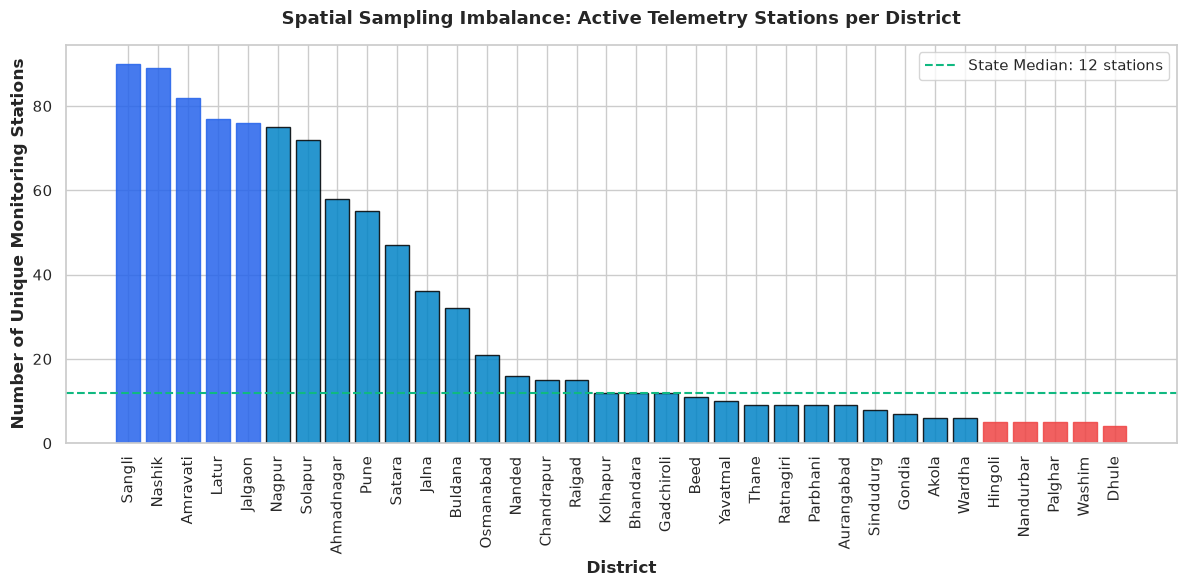

Highest Density District: Sangli (90 stations)
Lowest Density District:  Dhule (4 stations)
Density Ratio: Sangli has 22.5x more stations than Dhule!


In [5]:
# Calculate stations per district
st_counts = df_clean.groupby('District')['Station'].nunique().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(st_counts.index, st_counts.values, color='#0284c7', edgecolor='black', alpha=0.85)

# Highlight dense vs sparse extremes
for i, bar in enumerate(bars):
    if i < 5:
        bar.set_color('#2563eb') # Dense
    elif i >= len(bars) - 5:
        bar.set_color('#ef4444') # Sparse

plt.title("Spatial Sampling Imbalance: Active Telemetry Stations per District", fontweight='bold', pad=15)
plt.xlabel("District", fontweight='bold')
plt.ylabel("Number of Unique Monitoring Stations", fontweight='bold')
plt.xticks(rotation=90)
plt.axhline(st_counts.median(), color='#10b981', linestyle='--', label=f'State Median: {st_counts.median():.0f} stations')
plt.legend()
plt.tight_layout()
plt.show()

print(f"Highest Density District: {st_counts.idxmax()} ({st_counts.max()} stations)")
print(f"Lowest Density District:  {st_counts.idxmin()} ({st_counts.min()} stations)")
print(f"Density Ratio: Sangli has {st_counts.max() / st_counts.min():.1f}x more stations than Dhule!")


### 5. Alert Parameter Framework
We classify every observation according to Central Ground Water Board (CGWB) hydrological benchmarks:

| Depth Below Ground | Alert Status | Color Code | Hydrological Impact |
| :--- | :--- | :--- | :--- |
| **$\le 2.0	ext{ m}$** | **Flood / Waterlogging Risk** | 🔵 Blue (`#0284c7`) | Aquifer saturated; zero percolation; surface runoff flood risk. |
| **$2.0 - 5.0	ext{ m}$** | **Safe / High Water Table** | 🔷 Cyan (`#06b6d4`) | Healthy recharge reserve. |
| **$5.0 - 10.0	ext{ m}$** | **Normal Range** | 🟢 Green (`#10b981`) | Sustainable extraction baseline. |
| **$10.0 - 15.0	ext{ m}$** | **Moderate Drought Alert** | 🟠 Orange (`#f59e0b`) | Groundwater stress; irrigation conservation needed. |
| **$> 15.0	ext{ m}$** | **Severe Drought Alert** | 🔴 Red (`#ef4444`) | Over-exploited aquifer; borewells drying up; emergency alert. |


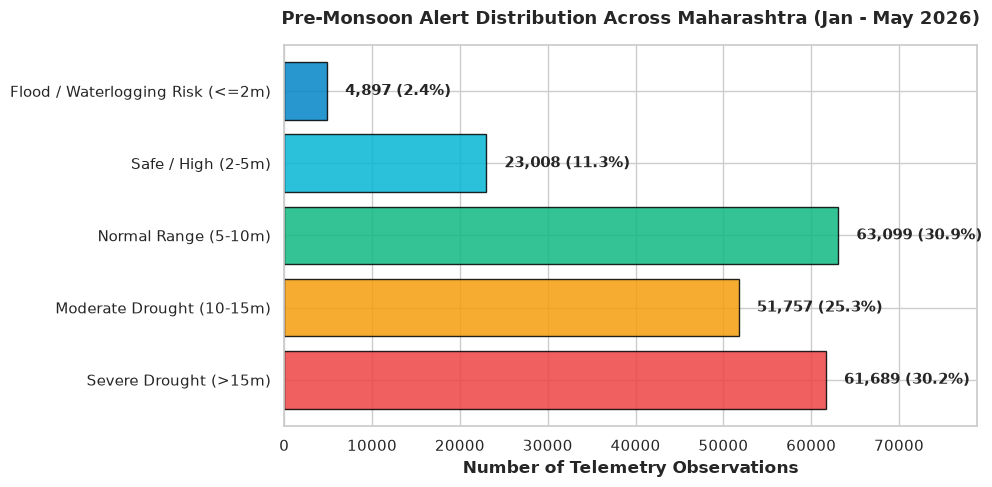

In [6]:
def classify_alert(d):
    if d <= 2.0:
        return "Flood / Waterlogging Risk (<=2m)"
    elif d <= 5.0:
        return "Safe / High (2-5m)"
    elif d <= 10.0:
        return "Normal Range (5-10m)"
    elif d <= 15.0:
        return "Moderate Drought (10-15m)"
    else:
        return "Severe Drought (>15m)"

df_clean['Alert_Status'] = df_clean['Depth_mbgl'].apply(classify_alert)

alert_order = [
    "Flood / Waterlogging Risk (<=2m)",
    "Safe / High (2-5m)",
    "Normal Range (5-10m)",
    "Moderate Drought (10-15m)",
    "Severe Drought (>15m)"
]
color_palette = ["#0284c7", "#06b6d4", "#10b981", "#f59e0b", "#ef4444"]

fig, ax = plt.subplots(figsize=(10, 5))
counts = df_clean['Alert_Status'].value_counts()[alert_order]
total = sum(counts)

bars = ax.barh(alert_order, counts, color=color_palette, edgecolor='black', alpha=0.85)
ax.set_title("Pre-Monsoon Alert Distribution Across Maharashtra (Jan - May 2026)", fontweight='bold', pad=15)
ax.set_xlabel("Number of Telemetry Observations", fontweight='bold')
ax.invert_yaxis()

for bar in bars:
    w = bar.get_width()
    pct = (w / total) * 100
    ax.text(w + total * 0.01, bar.get_y() + bar.get_height()/2, f"{w:,.0f} ({pct:.1f}%)", va='center', fontweight='bold')

plt.xlim(0, max(counts) * 1.25)
plt.tight_layout()
plt.show()


### 6. Temporal Depletion Trends (Pre-Monsoon Drawdown)
Plotting the daily median water depth across Maharashtra from January 1, 2026 to May 30, 2026 reveals continuous aquifer depletion during the hot summer dry season.


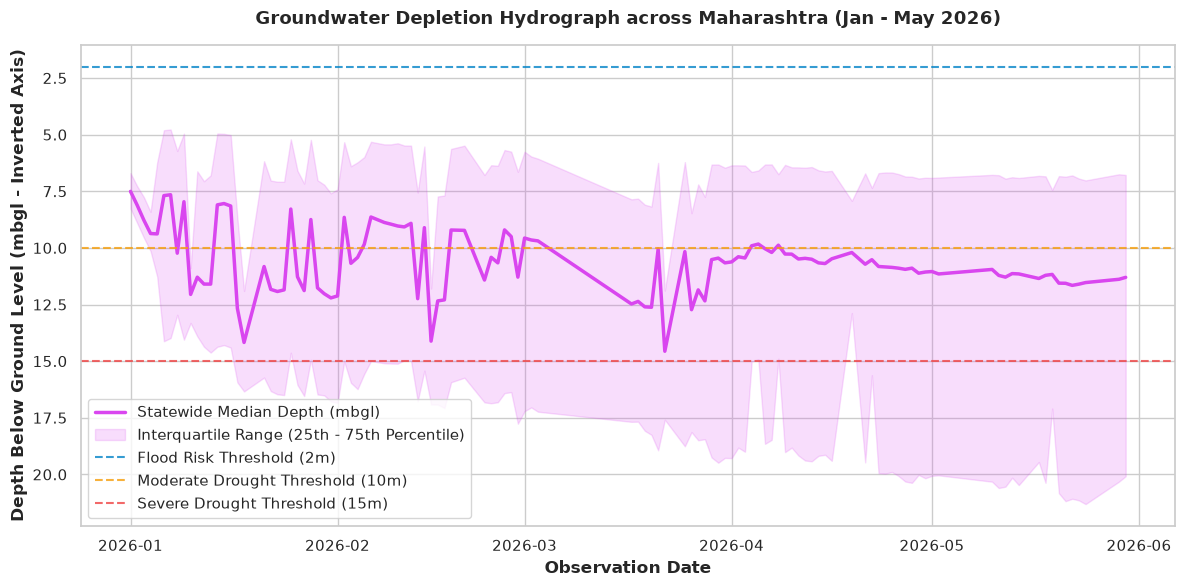

In [7]:
df_clean['Date'] = df_clean['DateTime'].dt.date
daily_stats = df_clean.groupby('Date')['Depth_mbgl'].agg([
    'median',
    lambda x: np.percentile(x, 25),
    lambda x: np.percentile(x, 75)
]).rename(columns={'<lambda_0>': 'p25', '<lambda_1>': 'p75'})
daily_stats.index = pd.to_datetime(daily_stats.index)

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(daily_stats.index, daily_stats['median'], color='#d946ef', lw=2.5, label='Statewide Median Depth (mbgl)')
ax.fill_between(daily_stats.index, daily_stats['p25'], daily_stats['p75'], color='#d946ef', alpha=0.18, label='Interquartile Range (25th - 75th Percentile)')

# Guideline Thresholds
ax.axhline(2.0, color='#0284c7', linestyle='--', alpha=0.8, label='Flood Risk Threshold (2m)')
ax.axhline(10.0, color='#f59e0b', linestyle='--', alpha=0.8, label='Moderate Drought Threshold (10m)')
ax.axhline(15.0, color='#ef4444', linestyle='--', alpha=0.8, label='Severe Drought Threshold (15m)')

ax.set_title("Groundwater Depletion Hydrograph across Maharashtra (Jan - May 2026)", fontweight='bold', pad=15)
ax.set_ylabel("Depth Below Ground Level (mbgl - Inverted Axis)", fontweight='bold')
ax.set_xlabel("Observation Date", fontweight='bold')
ax.invert_yaxis() # Invert so deeper water table appears physically lower!
ax.legend(loc='lower left', frameon=True)
plt.tight_layout()
plt.show()


### 7. District Vulnerability Ranking
Which districts in Maharashtra are facing the deepest groundwater depletion? Let's rank all 34 districts by mean depth.


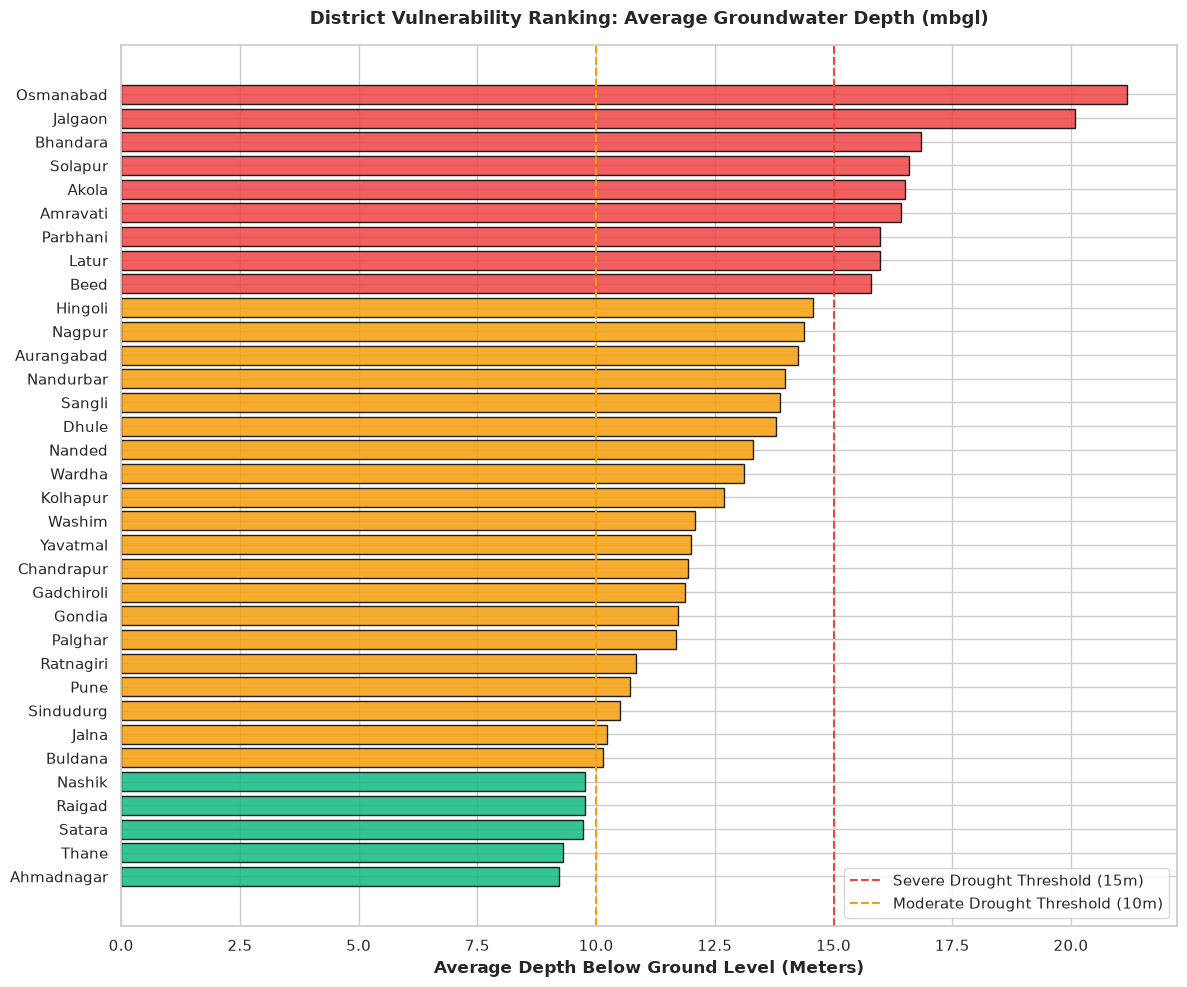

Top 5 Most Depleted (Driest) Districts:
 1. Osmanabad: 21.17 meters average depth
 2. Jalgaon: 20.10 meters average depth
 3. Bhandara: 16.85 meters average depth
 4. Solapur: 16.58 meters average depth
 5. Akola: 16.50 meters average depth


In [8]:
dist_mean = df_clean.groupby('District')['Depth_mbgl'].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(12, 10))
bar_colors = ['#ef4444' if v >= 15 else '#f59e0b' if v >= 10 else '#10b981' if v >= 5 else '#0284c7' for v in dist_mean.values]

ax.barh(dist_mean.index, dist_mean.values, color=bar_colors, edgecolor='black', alpha=0.85)
ax.axvline(15, color='#ef4444', linestyle='--', lw=1.5, label='Severe Drought Threshold (15m)')
ax.axvline(10, color='#f59e0b', linestyle='--', lw=1.5, label='Moderate Drought Threshold (10m)')
ax.set_title("District Vulnerability Ranking: Average Groundwater Depth (mbgl)", fontweight='bold', pad=15)
ax.set_xlabel("Average Depth Below Ground Level (Meters)", fontweight='bold')
ax.invert_yaxis()
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

print("Top 5 Most Depleted (Driest) Districts:")
for i, (d, val) in enumerate(dist_mean.head(5).items(), 1):
    print(f" {i}. {d}: {val:.2f} meters average depth")
